# 05 - Siamese Network and Classical Metric Learning for Iris Recognition

## Objective

This notebook implements a Siamese Network for iris verification using
classical deep metric learning.

Unlike Notebook 4, which performs closed-set iris identification using a
CNN and Softmax classifier, this notebook learns an embedding space in which:

- Images from the same iris identity are mapped close together.
- Images from different iris identities are mapped farther apart.

The model is trained using positive and negative iris image pairs with
Contrastive Loss.

The identity-disjoint train, validation, and test splits created in
Notebook 3 are used directly.

## Experimental Protocol

- Training identities are used only for model training.
- Validation identities are unseen during training and are used for:
    - model selection
    - threshold selection
    - hyperparameter monitoring
- Test identities are completely unseen during training and validation.
- The final test threshold is fixed using validation data.

## Outputs

This notebook produces:

1. A trained Siamese CNN encoder.
2. 128-dimensional normalized iris embeddings.
3. Verification accuracy.
4. ROC curve and AUC.
5. FAR and FRR.
6. Equal Error Rate (EER).
7. Validation-selected verification threshold.
8. Training curves.
9. Distance distribution plots.
10. Saved model and experimental results.

The learned embedding model will be used in later notebooks for
few-shot iris recognition experiments.

In [43]:
# ============================================================
# CELL 2: Import libraries
# ============================================================

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms


print("All libraries imported successfully.")

All libraries imported successfully.


In [44]:
# ============================================================
# CELL 3: Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed()


print(f"Random seed set to: {SEED}")

Random seed set to: 42


In [45]:
# ============================================================
# CELL 4: Configuration
# ============================================================


# ------------------------------------------------------------
# Notebook 3 output directory
# ------------------------------------------------------------

DATA_SPLITS_ROOT = Path("../data_splits")


# ------------------------------------------------------------
# Notebook 5 output directory
# ------------------------------------------------------------

OUTPUT_DIR = Path("../siamese_metric_learning")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Image configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224


# ------------------------------------------------------------
# Encoder
# ------------------------------------------------------------
# Pretrained ResNet instead of the 4-layer CNN trained from scratch.
# Do NOT warm-start from the Notebook 4 checkpoint: Notebook 4 is a
# closed-set classifier and may have seen identities that are in this
# notebook's validation/test splits, which would leak.

BACKBONE = "resnet34"          # "resnet18" (faster) | "resnet34" | "resnet50"


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

BATCH_SIZE = 16                # PAIRS per batch = 32 images (fits 4 GB VRAM)

NUM_EPOCHS = 60                # was 25 - still improving at the last epoch

BACKBONE_LR = 1e-4             # pretrained trunk: small LR

HEAD_LR = 1e-3                 # new embedding layer: larger LR

LEARNING_RATE = HEAD_LR        # kept so the config-saving cell still works

WEIGHT_DECAY = 5e-4

PATIENCE = 12                  # was 8 - more room before stopping

NUM_WORKERS = 0                # Windows-safe


# ------------------------------------------------------------
# Metric learning configuration
# ------------------------------------------------------------

EMBEDDING_DIM = 128

CONTRASTIVE_MARGIN = 1.0


# ------------------------------------------------------------
# Pair configuration
# ------------------------------------------------------------
# Pairs are re-sampled every epoch, so 6,400 fresh pairs per epoch
# over 60 epochs sees 384,000 different pairs total.

TRAIN_PAIRS_PER_EPOCH = 6400

VALIDATION_PAIRS = 5000

TEST_PAIRS = 5000


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# GTX 16-series has no Tensor Cores: fp16 gave NaN losses in Notebook 4
# and no speed benefit, so mixed precision stays off.
USE_AMP = False


print("Data splits directory:", DATA_SPLITS_ROOT)

print("Output directory:", OUTPUT_DIR)

print("Backbone:", BACKBONE)

print("Device:", DEVICE)

print("Mixed precision:", USE_AMP)

print("Epochs:", NUM_EPOCHS)

print("Pairs per batch:", BATCH_SIZE)

Data splits directory: ..\data_splits
Output directory: ..\siamese_metric_learning
Backbone: resnet34
Device: cuda
Mixed precision: False
Epochs: 60
Pairs per batch: 16


In [46]:
# ============================================================
# CELL 5: Verify Notebook 3 output directory
# ============================================================

if not DATA_SPLITS_ROOT.exists():

    raise FileNotFoundError(
        f"Notebook 3 output directory was not found:\n"
        f"{DATA_SPLITS_ROOT}\n\n"
        "Please check the output path used in Notebook 3."
    )


available_files = sorted(

    [
        file.name
        for file in DATA_SPLITS_ROOT.iterdir()
        if file.is_file()
    ]

)


print("Files found in Notebook 3 output directory:\n")

for file_name in available_files:

    print("-", file_name)

Files found in Notebook 3 output directory:

- 1shot_test_query.csv
- 1shot_test_support.csv
- 1shot_train_query.csv
- 1shot_train_support.csv
- 1shot_validation_query.csv
- 1shot_validation_support.csv
- 3shot_test_query.csv
- 3shot_test_support.csv
- 3shot_train_query.csv
- 3shot_train_support.csv
- 3shot_validation_query.csv
- 3shot_validation_support.csv
- 5shot_test_query.csv
- 5shot_test_support.csv
- 5shot_train_query.csv
- 5shot_train_support.csv
- 5shot_validation_query.csv
- 5shot_validation_support.csv
- few_shot_summary.csv
- reconstructed_metadata.csv
- test.csv
- train.csv
- validation.csv


In [47]:
# ============================================================
# CELL 6: Locate Notebook 3 split CSV files
# ============================================================


def find_csv(possible_names):

    for name in possible_names:

        path = DATA_SPLITS_ROOT / name

        if path.exists():

            return path

    return None


TRAIN_CSV = find_csv(
    [
        "train.csv",
        "training.csv"
    ]
)


VALIDATION_CSV = find_csv(
    [
        "validation.csv",
        "val.csv"
    ]
)


TEST_CSV = find_csv(
    [
        "test.csv"
    ]
)


if TRAIN_CSV is None:

    raise FileNotFoundError(
        "Training CSV was not found."
    )


if VALIDATION_CSV is None:

    raise FileNotFoundError(
        "Validation CSV was not found."
    )


if TEST_CSV is None:

    raise FileNotFoundError(
        "Test CSV was not found."
    )


print("Detected files:\n")

print("Train:", TRAIN_CSV)

print("Validation:", VALIDATION_CSV)

print("Test:", TEST_CSV)

Detected files:

Train: ..\data_splits\train.csv
Validation: ..\data_splits\validation.csv
Test: ..\data_splits\test.csv


In [48]:
# ============================================================
# CELL 7: Load Notebook 3 data splits
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV
)


validation_df = pd.read_csv(
    VALIDATION_CSV
)


test_df = pd.read_csv(
    TEST_CSV
)


print("=" * 60)

print("DATASET SPLITS")

print("=" * 60)


print("\nTrain shape:", train_df.shape)

print("Validation shape:", validation_df.shape)

print("Test shape:", test_df.shape)


print("\nAvailable columns:")

print(
    train_df.columns.tolist()
)


display(
    train_df.head()
)

DATASET SPLITS

Train shape: (14000, 6)
Validation shape: (3000, 6)
Test shape: (3000, 6)

Available columns:
['subject_id', 'eye', 'identity', 'image_index', 'image_name', 'processed_path']


,subject_id,eye,identity,image_index,image_name,processed_path
0,0,L,000-L,0,000_L_00_norm.png,..\outputs\preprocessed_iris\000_L_00_norm.png
1,0,L,000-L,1,000_L_01_norm.png,..\outputs\preprocessed_iris\000_L_01_norm.png
2,0,L,000-L,2,000_L_02_norm.png,..\outputs\preprocessed_iris\000_L_02_norm.png
3,0,L,000-L,3,000_L_03_norm.png,..\outputs\preprocessed_iris\000_L_03_norm.png
4,0,L,000-L,4,000_L_04_norm.png,..\outputs\preprocessed_iris\000_L_04_norm.png


In [49]:
# ============================================================
# CELL 8: Detect identity and image path columns
# ============================================================


IDENTITY_CANDIDATES = [

    "identity",

    "eye_id",

    "subject_id",

    "class_id",

    "label"

]


PATH_CANDIDATES = [

    "processed_path",

    "image_path",

    "path",

    "filepath",

    "file_path"

]


def find_column(
    dataframe,
    candidates
):

    for column in candidates:

        if column in dataframe.columns:

            return column

    return None


IDENTITY_COLUMN = find_column(

    train_df,

    IDENTITY_CANDIDATES

)


PATH_COLUMN = find_column(

    train_df,

    PATH_CANDIDATES

)


if IDENTITY_COLUMN is None:

    raise ValueError(
        "Could not detect the identity column.\n\n"
        f"Available columns:\n"
        f"{train_df.columns.tolist()}"
    )


if PATH_COLUMN is None:

    raise ValueError(
        "Could not detect the image path column.\n\n"
        f"Available columns:\n"
        f"{train_df.columns.tolist()}"
    )


print(
    "Identity column detected:",
    IDENTITY_COLUMN
)


print(
    "Image path column detected:",
    PATH_COLUMN
)

Identity column detected: identity
Image path column detected: processed_path


In [50]:
# ============================================================
# CELL 9: Robust image path handling
# ============================================================


def resolve_image_path(path_value):

    path_value = str(
        path_value
    )


    path = Path(
        path_value
    )


    # Case 1: Already valid absolute path

    if path.exists():

        return str(
            path.resolve()
        )


    # Case 2: Relative to Notebook 3 output directory

    candidate = DATA_SPLITS_ROOT / path

    if candidate.exists():

        return str(
            candidate.resolve()
        )


    # Case 3: Relative to current working directory

    candidate = Path.cwd() / path

    if candidate.exists():

        return str(
            candidate.resolve()
        )


    # Return original path for later error reporting

    return str(
        path
    )


for dataframe in [
    train_df,
    validation_df,
    test_df
]:

    dataframe[PATH_COLUMN] = dataframe[
        PATH_COLUMN
    ].apply(
        resolve_image_path
    )


print(
    "Image paths processed."
)

Image paths processed.


In [51]:
# ============================================================
# CELL 10: Verify all image files
# ============================================================


def verify_paths(
    dataframe,
    split_name
):

    missing = dataframe.loc[

        ~dataframe[
            PATH_COLUMN
        ].apply(
            lambda path: Path(path).exists()
        )

    ]


    print(
        f"{split_name} missing images:",
        len(missing)
    )


    if len(missing) > 0:

        print(
            "\nExamples of missing paths:"
        )

        display(
            missing[
                [
                    IDENTITY_COLUMN,
                    PATH_COLUMN
                ]
            ].head()
        )


        raise FileNotFoundError(
            f"{split_name} contains missing image files."
        )


verify_paths(
    train_df,
    "Training"
)


verify_paths(
    validation_df,
    "Validation"
)


verify_paths(
    test_df,
    "Test"
)


print(
    "\n✓ All image files were found successfully."
)

Training missing images: 0
Validation missing images: 0
Test missing images: 0

✓ All image files were found successfully.


In [52]:
# ============================================================
# CELL 11: Verify identity-disjoint protocol
# ============================================================


train_ids = set(
    train_df[
        IDENTITY_COLUMN
    ].unique()
)


validation_ids = set(
    validation_df[
        IDENTITY_COLUMN
    ].unique()
)


test_ids = set(
    test_df[
        IDENTITY_COLUMN
    ].unique()
)


print("=" * 60)

print("IDENTITY-DISJOINT SPLIT VERIFICATION")

print("=" * 60)


print(
    "\nTrain identities:",
    len(train_ids)
)


print(
    "Validation identities:",
    len(validation_ids)
)


print(
    "Test identities:",
    len(test_ids)
)


train_validation_overlap = len(
    train_ids & validation_ids
)


train_test_overlap = len(
    train_ids & test_ids
)


validation_test_overlap = len(
    validation_ids & test_ids
)


print(
    "\nTrain ∩ Validation:",
    train_validation_overlap
)


print(
    "Train ∩ Test:",
    train_test_overlap
)


print(
    "Validation ∩ Test:",
    validation_test_overlap
)


assert train_validation_overlap == 0

assert train_test_overlap == 0

assert validation_test_overlap == 0


print(
    "\n✓ All splits are identity-disjoint."
)

IDENTITY-DISJOINT SPLIT VERIFICATION

Train identities: 1400
Validation identities: 300
Test identities: 300

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ All splits are identity-disjoint.


In [53]:
# ============================================================
# CELL 12: Dataset summary
# ============================================================


def print_summary(
    dataframe,
    split_name
):

    images_per_identity = (

        dataframe
        .groupby(
            IDENTITY_COLUMN
        )
        .size()

    )


    print("\n" + "=" * 60)

    print(
        split_name.upper()
    )

    print("=" * 60)


    print(
        "Total images:",
        len(dataframe)
    )


    print(
        "Unique identities:",
        dataframe[
            IDENTITY_COLUMN
        ].nunique()
    )


    print(
        "Minimum images per identity:",
        images_per_identity.min()
    )


    print(
        "Maximum images per identity:",
        images_per_identity.max()
    )


    print(
        "Average images per identity:",
        round(
            images_per_identity.mean(),
            2
        )
    )


print_summary(
    train_df,
    "Training Split"
)


print_summary(
    validation_df,
    "Validation Split"
)


print_summary(
    test_df,
    "Test Split"
)


TRAINING SPLIT
Total images: 14000
Unique identities: 1400
Minimum images per identity: 10
Maximum images per identity: 10
Average images per identity: 10.0

VALIDATION SPLIT
Total images: 3000
Unique identities: 300
Minimum images per identity: 10
Maximum images per identity: 10
Average images per identity: 10.0

TEST SPLIT
Total images: 3000
Unique identities: 300
Minimum images per identity: 10
Maximum images per identity: 10
Average images per identity: 10.0


In [54]:
# ============================================================
# CELL 13: Image transformations
# ============================================================
#
# Changes vs. the original:
#  - RandomHorizontalFlip removed. Each image in a pair is transformed
#    independently, so a genuine pair could end up with one flipped and
#    one unflipped eye, and a flipped left iris resembles a right iris.
#    That teaches the network the wrong notion of identity.
#  - Stronger geometric / illumination / occlusion augmentation to
#    reduce overfitting on the training identities.


NORMALIZE_MEAN = [0.485, 0.456, 0.406]

NORMALIZE_STD = [0.229, 0.224, 0.225]


train_transform = transforms.Compose(

    [

        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.RandomApply(
            [
                transforms.RandomAffine(
                    degrees=10,
                    translate=(0.06, 0.06),
                    scale=(0.90, 1.10),
                    shear=4,
                    fill=0
                )
            ],
            p=0.8
        ),

        transforms.ColorJitter(
            brightness=0.30,
            contrast=0.30
        ),

        transforms.RandomApply(
            [
                transforms.GaussianBlur(
                    kernel_size=3,
                    sigma=(0.1, 1.2)
                )
            ],
            p=0.25
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=NORMALIZE_MEAN,
            std=NORMALIZE_STD
        ),

        transforms.RandomErasing(
            p=0.30,
            scale=(0.02, 0.12),
            ratio=(0.3, 3.3),
            value=0
        )

    ]

)


evaluation_transform = transforms.Compose(

    [

        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=NORMALIZE_MEAN,
            std=NORMALIZE_STD
        )

    ]

)


print("Image transformations configured.")


Image transformations configured.


In [55]:
# ============================================================
# CELL 14: Siamese pair dataset
# ============================================================


class SiamesePairDataset(
    Dataset
):


    def __init__(

        self,

        dataframe,

        identity_column,

        path_column,

        num_pairs,

        transform=None,

        seed=42

    ):


        self.dataframe = (

            dataframe
            .reset_index(
                drop=True
            )
            .copy()

        )


        self.identity_column = (
            identity_column
        )


        self.path_column = (
            path_column
        )


        self.num_pairs = (
            num_pairs
        )


        self.transform = (
            transform
        )


        self.seed = (
            seed
        )


        self.identity_to_indices = {

            identity:

            group.index.tolist()

            for identity, group

            in self.dataframe.groupby(
                self.identity_column
            )

        }


        self.identities = list(
            self.identity_to_indices.keys()
        )


        self.valid_positive_ids = [

            identity

            for identity, indices

            in self.identity_to_indices.items()

            if len(indices) >= 2

        ]


        if len(
            self.valid_positive_ids
        ) == 0:

            raise ValueError(
                "No identities contain at least "
                "two images for positive pair generation."
            )


        self.create_pairs()


    def create_pairs(
        self
    ):


        rng = random.Random(
            self.seed
        )


        self.pairs = []


        num_positive = (
            self.num_pairs // 2
        )


        num_negative = (
            self.num_pairs -
            num_positive
        )


        # ----------------------------------------------------
        # Positive pairs
        # Label = 0
        # ----------------------------------------------------

        for _ in range(
            num_positive
        ):


            identity = rng.choice(

                self.valid_positive_ids

            )


            index1, index2 = rng.sample(

                self.identity_to_indices[
                    identity
                ],

                2

            )


            self.pairs.append(

                (
                    index1,
                    index2,
                    0.0
                )

            )


        # ----------------------------------------------------
        # Negative pairs
        # Label = 1
        # ----------------------------------------------------

        for _ in range(
            num_negative
        ):


            identity1, identity2 = rng.sample(

                self.identities,

                2

            )


            index1 = rng.choice(

                self.identity_to_indices[
                    identity1
                ]

            )


            index2 = rng.choice(

                self.identity_to_indices[
                    identity2
                ]

            )


            self.pairs.append(

                (
                    index1,
                    index2,
                    1.0
                )

            )


        rng.shuffle(
            self.pairs
        )


    def regenerate_pairs(
        self,
        epoch
    ):


        self.seed = (
            SEED + epoch
        )


        self.create_pairs()


    def __len__(
        self
    ):


        return len(
            self.pairs
        )


    def __getitem__(
        self,
        index
    ):


        index1, index2, label = (

            self.pairs[index]

        )


        path1 = self.dataframe.iloc[
            index1
        ][
            self.path_column
        ]


        path2 = self.dataframe.iloc[
            index2
        ][
            self.path_column
        ]


        image1 = Image.open(
            path1
        ).convert(
            "RGB"
        )


        image2 = Image.open(
            path2
        ).convert(
            "RGB"
        )


        if self.transform is not None:


            image1 = self.transform(
                image1
            )


            image2 = self.transform(
                image2
            )


        label = torch.tensor(

            label,

            dtype=torch.float32

        )


        return (

            image1,

            image2,

            label

        )

In [56]:
# ============================================================
# CELL 15: Create pair datasets
# ============================================================


train_pair_dataset = SiamesePairDataset(

    dataframe=train_df,

    identity_column=IDENTITY_COLUMN,

    path_column=PATH_COLUMN,

    num_pairs=TRAIN_PAIRS_PER_EPOCH,

    transform=train_transform,

    seed=SEED

)


validation_pair_dataset = SiamesePairDataset(

    dataframe=validation_df,

    identity_column=IDENTITY_COLUMN,

    path_column=PATH_COLUMN,

    num_pairs=VALIDATION_PAIRS,

    transform=evaluation_transform,

    seed=SEED

)


test_pair_dataset = SiamesePairDataset(

    dataframe=test_df,

    identity_column=IDENTITY_COLUMN,

    path_column=PATH_COLUMN,

    num_pairs=TEST_PAIRS,

    transform=evaluation_transform,

    seed=SEED + 1

)


print("Pair datasets created successfully.\n")

print(
    "Training pairs:",
    len(train_pair_dataset)
)


print(
    "Validation pairs:",
    len(validation_pair_dataset)
)


print(
    "Test pairs:",
    len(test_pair_dataset)
)

Pair datasets created successfully.

Training pairs: 6400
Validation pairs: 5000
Test pairs: 5000


In [57]:
# ============================================================
# CELL 16: Save validation and test pair definitions
# ============================================================


def save_pair_definitions(
    dataset,
    output_path
):


    records = []


    for index1, index2, label in dataset.pairs:


        records.append(

            {

                "image1_path":

                    dataset.dataframe.iloc[
                        index1
                    ][
                        dataset.path_column
                    ],

                "image2_path":

                    dataset.dataframe.iloc[
                        index2
                    ][
                        dataset.path_column
                    ],

                "label":

                    int(label)

            }

        )


    pairs_df = pd.DataFrame(
        records
    )


    pairs_df.to_csv(

        output_path,

        index=False

    )


VALIDATION_PAIRS_PATH = OUTPUT_DIR / (
    "validation_pairs.csv"
)


TEST_PAIRS_PATH = OUTPUT_DIR / (
    "test_pairs.csv"
)


save_pair_definitions(

    validation_pair_dataset,

    VALIDATION_PAIRS_PATH

)


save_pair_definitions(

    test_pair_dataset,

    TEST_PAIRS_PATH

)


print(
    "Validation and test pair definitions saved."
)

Validation and test pair definitions saved.


In [58]:
# ============================================================
# CELL 17: Create DataLoaders
# ============================================================


loader_kwargs = {

    "batch_size":

        BATCH_SIZE,

    "num_workers":

        NUM_WORKERS,

    "pin_memory":

        DEVICE.type == "cuda"

}


if NUM_WORKERS > 0:

    loader_kwargs[
        "persistent_workers"
    ] = True


train_loader = DataLoader(

    train_pair_dataset,

    shuffle=True,

    **loader_kwargs

)


validation_loader = DataLoader(

    validation_pair_dataset,

    shuffle=False,

    **loader_kwargs

)


test_loader = DataLoader(

    test_pair_dataset,

    shuffle=False,

    **loader_kwargs

)


print(
    "DataLoaders created successfully."
)

DataLoaders created successfully.


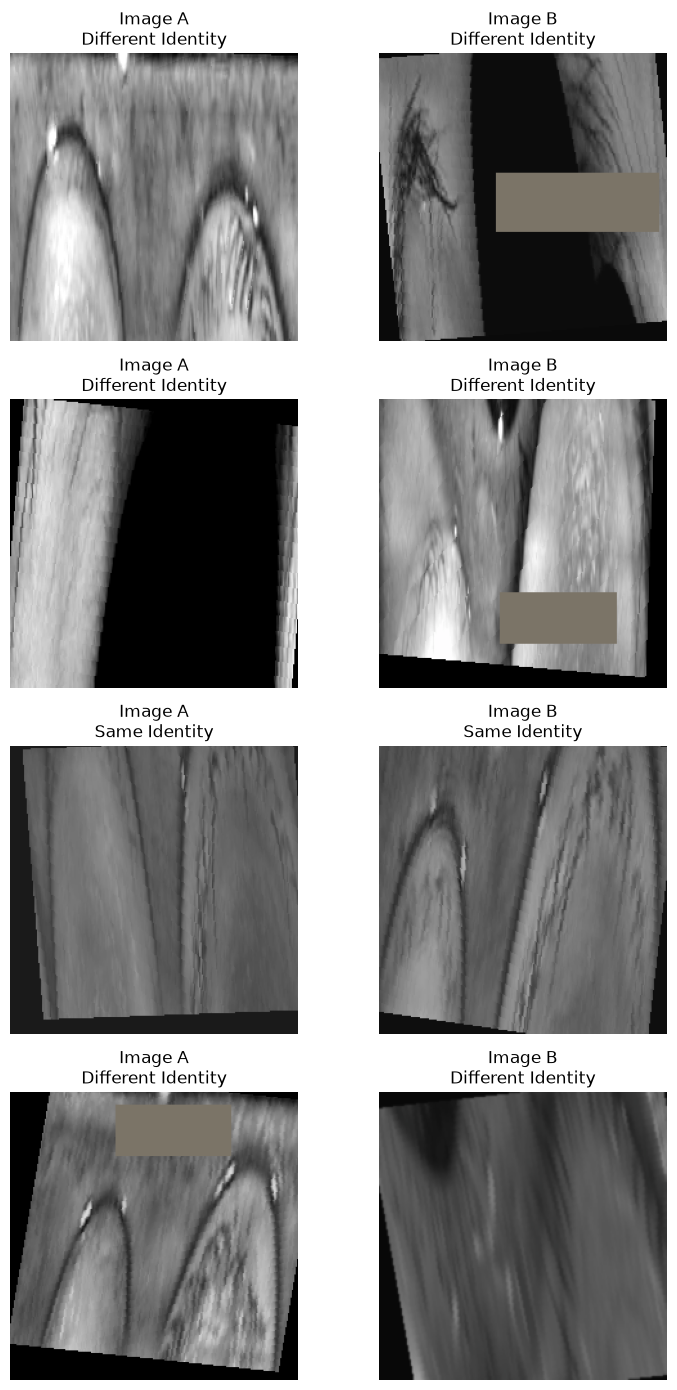

In [59]:
# ============================================================
# CELL 18: Visualize sample pairs
# ============================================================


def denormalize_image(
    image_tensor
):


    image = image_tensor.clone()


    mean = torch.tensor(
        NORMALIZE_MEAN
    ).view(
        3,
        1,
        1
    )


    std = torch.tensor(
        NORMALIZE_STD
    ).view(
        3,
        1,
        1
    )


    image = (

        image * std +
        mean

    )


    image = torch.clamp(

        image,

        0,
        1

    )


    return image


image1_batch, image2_batch, label_batch = next(

    iter(
        train_loader
    )

)


fig, axes = plt.subplots(

    4,

    2,

    figsize=(
        8,
        14
    )

)


for row in range(4):


    image1 = denormalize_image(

        image1_batch[row]

    ).permute(
        1,
        2,
        0
    ).numpy()


    image2 = denormalize_image(

        image2_batch[row]

    ).permute(
        1,
        2,
        0
    ).numpy()


    pair_type = (

        "Same Identity"

        if label_batch[
            row
        ].item() == 0

        else

        "Different Identity"

    )


    axes[row, 0].imshow(
        image1
    )


    axes[row, 1].imshow(
        image2
    )


    axes[row, 0].set_title(

        f"Image A\n{pair_type}"

    )


    axes[row, 1].set_title(

        f"Image B\n{pair_type}"

    )


    axes[row, 0].axis(
        "off"
    )


    axes[row, 1].axis(
        "off"
    )


plt.tight_layout()

plt.show()

In [60]:
# ============================================================
# CELL 19: Siamese CNN encoder (pretrained ResNet + BN-neck)
# ============================================================
#
# Replaces the 4-block CNN trained from scratch. A from-scratch network
# on ~11k training images cannot learn a strong iris embedding; an
# ImageNet-pretrained ResNet fine-tuned with contrastive loss can.

from torchvision.models import (
    resnet18, ResNet18_Weights,
    resnet34, ResNet34_Weights,
    resnet50, ResNet50_Weights,
)


def build_backbone(name):

    if name == "resnet18":

        trunk = resnet18(weights=ResNet18_Weights.DEFAULT)

    elif name == "resnet34":

        trunk = resnet34(weights=ResNet34_Weights.DEFAULT)

    elif name == "resnet50":

        trunk = resnet50(weights=ResNet50_Weights.DEFAULT)

    else:

        raise ValueError(f"Unknown backbone: {name}")

    num_features = trunk.fc.in_features

    trunk.fc = nn.Identity()

    return trunk, num_features


class SiameseEncoder(nn.Module):

    def __init__(
        self,
        embedding_dim=128,
        backbone_name=None,
        dropout=0.2
    ):

        super().__init__()

        backbone_name = backbone_name or BACKBONE

        self.backbone, num_features = build_backbone(backbone_name)

        # BN-neck: Linear -> BatchNorm1d, no ReLU, then L2 normalisation
        self.embedding_layer = nn.Sequential(

            nn.Dropout(dropout),

            nn.Linear(
                num_features,
                embedding_dim,
                bias=False
            ),

            nn.BatchNorm1d(embedding_dim)

        )

    def forward(self, x):

        features = self.backbone(x)

        embedding = self.embedding_layer(features)

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

        return embedding


In [61]:
# ============================================================
# CELL 20: Siamese Network
# ============================================================


class SiameseNetwork(
    nn.Module
):


    def __init__(
        self,
        embedding_dim=128
    ):


        super().__init__()


        self.encoder = SiameseEncoder(

            embedding_dim=
            embedding_dim

        )


    def forward(

        self,

        image1,

        image2

    ):


        embedding1 = self.encoder(
            image1
        )


        embedding2 = self.encoder(
            image2
        )


        return (

            embedding1,

            embedding2

        )

In [62]:
# ============================================================
# CELL 21: Contrastive Loss
# ============================================================


class ContrastiveLoss(
    nn.Module
):


    def __init__(
        self,
        margin=1.0
    ):


        super().__init__()


        self.margin = margin


    def forward(

        self,

        embedding1,

        embedding2,

        labels

    ):


        distances = F.pairwise_distance(

            embedding1,

            embedding2

        )


        # Genuine pairs:
        # label = 0
        # Minimize distance

        genuine_loss = (

            (1 - labels)

            *

            distances.pow(2)

        )


        # Impostor pairs:
        # label = 1
        # Push distance above margin

        impostor_loss = (

            labels

            *

            torch.clamp(

                self.margin -

                distances,

                min=0.0

            ).pow(2)

        )


        loss = (

            genuine_loss +

            impostor_loss

        ).mean()


        return (

            loss,

            distances

        )

In [63]:
# ============================================================
# CELL 22: Initialize model, loss, optimizer
# ============================================================

import json


model = SiameseNetwork(
    embedding_dim=EMBEDDING_DIM
).to(DEVICE)


criterion = ContrastiveLoss(
    margin=CONTRASTIVE_MARGIN
)


# ------------------------------------------------------------
# Discriminative learning rates
# ------------------------------------------------------------
# Pretrained backbone: small LR. New embedding layer: 10x larger.
# BatchNorm / bias parameters get no weight decay.

def build_param_groups(model, backbone_lr, head_lr, weight_decay):

    groups = {
        "backbone_decay": [],
        "backbone_no_decay": [],
        "head_decay": [],
        "head_no_decay": [],
    }

    for name, parameter in model.named_parameters():

        if not parameter.requires_grad:
            continue

        is_backbone = "backbone" in name

        no_decay = parameter.ndim <= 1 or name.endswith(".bias")

        key = (
            ("backbone_" if is_backbone else "head_")
            + ("no_decay" if no_decay else "decay")
        )

        groups[key].append(parameter)

    return [
        {"params": groups["backbone_decay"],
         "lr": backbone_lr, "weight_decay": weight_decay},

        {"params": groups["backbone_no_decay"],
         "lr": backbone_lr, "weight_decay": 0.0},

        {"params": groups["head_decay"],
         "lr": head_lr, "weight_decay": weight_decay},

        {"params": groups["head_no_decay"],
         "lr": head_lr, "weight_decay": 0.0},
    ]


optimizer = optim.AdamW(
    build_param_groups(
        model,
        BACKBONE_LR,
        HEAD_LR,
        WEIGHT_DECAY
    )
)


scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


if USE_AMP:

    scaler = torch.amp.GradScaler("cuda")

else:

    scaler = None


# ------------------------------------------------------------
# Save the encoder recipe so later notebooks (few-shot) can rebuild
# exactly this architecture from the checkpoint.
# ------------------------------------------------------------

ENCODER_CONFIG_PATH = OUTPUT_DIR / "encoder_config.json"

with open(ENCODER_CONFIG_PATH, "w") as file:

    json.dump(
        {
            "backbone": BACKBONE,
            "embedding_dim": EMBEDDING_DIM,
            "image_size": IMAGE_SIZE,
            "normalize_mean": NORMALIZE_MEAN,
            "normalize_std": NORMALIZE_STD,
        },
        file,
        indent=2
    )


total_parameters = sum(p.numel() for p in model.parameters())

print("Backbone:", BACKBONE)

print("Embedding dimension:", EMBEDDING_DIM)

print("Contrastive margin:", CONTRASTIVE_MARGIN)

print("Total parameters:", total_parameters)

print("Encoder config saved to:", ENCODER_CONFIG_PATH)


Backbone: resnet34
Embedding dimension: 128
Contrastive margin: 1.0
Total parameters: 21350464
Encoder config saved to: ..\siamese_metric_learning\encoder_config.json


In [64]:
# ============================================================
# CELL 23: Distance-based prediction
# ============================================================


def predict_from_distance(

    distances,

    threshold

):


    # distance <= threshold
    # means SAME identity
    # predicted label = 0


    predictions = (

        distances > threshold

    ).astype(
        int
    )


    return predictions

In [65]:
# ============================================================
# CELL 24: Train one epoch
# ============================================================


def train_one_epoch(

    model,

    dataloader,

    criterion,

    optimizer

):


    model.train()


    running_loss = 0.0


    for image1, image2, labels in tqdm(

        dataloader,

        desc="Training",

        leave=False

    ):


        image1 = image1.to(

            DEVICE,

            non_blocking=True

        )


        image2 = image2.to(

            DEVICE,

            non_blocking=True

        )


        labels = labels.to(

            DEVICE,

            non_blocking=True

        )


        optimizer.zero_grad()


        if USE_AMP:


            with torch.amp.autocast(

                device_type="cuda"

            ):


                embedding1, embedding2 = model(

                    image1,

                    image2

                )


                loss, _ = criterion(

                    embedding1,

                    embedding2,

                    labels

                )


            scaler.scale(
                loss
            ).backward()


            scaler.unscale_(
                optimizer
            )


            torch.nn.utils.clip_grad_norm_(

                model.parameters(),

                max_norm=5.0

            )


            scaler.step(
                optimizer
            )


            scaler.update()


        else:


            embedding1, embedding2 = model(

                image1,

                image2

            )


            loss, _ = criterion(

                embedding1,

                embedding2,

                labels

            )


            loss.backward()


            torch.nn.utils.clip_grad_norm_(

                model.parameters(),

                max_norm=5.0

            )


            optimizer.step()


        running_loss += (

            loss.item()

            *

            image1.size(0)

        )


    epoch_loss = (

        running_loss

        /

        len(
            dataloader.dataset
        )

    )


    return epoch_loss

In [66]:
# ============================================================
# CELL 25: Evaluate model
# ============================================================


def evaluate_model(

    model,

    dataloader,

    criterion

):


    model.eval()


    running_loss = 0.0


    all_distances = []


    all_labels = []


    with torch.no_grad():


        for image1, image2, labels in tqdm(

            dataloader,

            desc="Evaluating",

            leave=False

        ):


            image1 = image1.to(

                DEVICE,

                non_blocking=True

            )


            image2 = image2.to(

                DEVICE,

                non_blocking=True

            )


            labels = labels.to(

                DEVICE,

                non_blocking=True

            )


            if USE_AMP:


                with torch.amp.autocast(

                    device_type="cuda"

                ):


                    embedding1, embedding2 = model(

                        image1,

                        image2

                    )


                    loss, distances = criterion(

                        embedding1,

                        embedding2,

                        labels

                    )


            else:


                embedding1, embedding2 = model(

                    image1,

                    image2

                )


                loss, distances = criterion(

                    embedding1,

                    embedding2,

                    labels

                )


            running_loss += (

                loss.item()

                *

                image1.size(0)

            )


            all_distances.extend(

                distances
                .detach()
                .cpu()
                .numpy()

            )


            all_labels.extend(

                labels
                .detach()
                .cpu()
                .numpy()

            )


    epoch_loss = (

        running_loss

        /

        len(
            dataloader.dataset
        )

    )


    return (

        epoch_loss,

        np.array(
            all_distances
        ),

        np.array(
            all_labels
        )

    )

In [67]:
# ============================================================
# CELL 26: Verification metrics
# ============================================================


def calculate_far_frr(

    distances,

    labels,

    threshold

):


    predictions = predict_from_distance(

        distances,

        threshold

    )


    genuine_mask = (

        labels == 0

    )


    impostor_mask = (

        labels == 1

    )


    # Genuine pair predicted as different

    false_rejections = np.sum(

        predictions[
            genuine_mask
        ] == 1

    )


    # Impostor pair predicted as same

    false_accepts = np.sum(

        predictions[
            impostor_mask
        ] == 0

    )


    genuine_count = np.sum(
        genuine_mask
    )


    impostor_count = np.sum(
        impostor_mask
    )


    FRR = (

        false_rejections /
        genuine_count

        if genuine_count > 0

        else 0.0

    )


    FAR = (

        false_accepts /
        impostor_count

        if impostor_count > 0

        else 0.0

    )


    return FAR, FRR

In [68]:
# ============================================================
# CELL 27: Threshold selection and EER
# ============================================================


def get_validation_metrics(

    distances,

    labels

):


    # Convert to:
    #
    # 1 = genuine / same
    # 0 = impostor / different

    genuine_labels = (

        1 - labels

    )


    # Smaller distance means more genuine,
    # so negative distance is used as score.

    scores = (

        -distances

    )


    fpr, tpr, roc_thresholds = roc_curve(

        genuine_labels,

        scores

    )


    auc_score = roc_auc_score(

        genuine_labels,

        scores

    )


    # Youden's J statistic

    youden_j = (

        tpr - fpr

    )


    best_index = np.argmax(

        youden_j

    )


    best_score_threshold = (

        roc_thresholds[
            best_index
        ]

    )


    # Convert score threshold back to distance threshold

    best_distance_threshold = (

        -best_score_threshold

    )


    predictions = predict_from_distance(

        distances,

        best_distance_threshold

    )


    accuracy = accuracy_score(

        labels,

        predictions

    )


    # EER approximation from ROC points

    fnr = (

        1 - tpr

    )


    eer_index = np.argmin(

        np.abs(

            fpr - fnr

        )

    )


    eer = (

        fpr[
            eer_index
        ]

        +

        fnr[
            eer_index
        ]

    ) / 2


    eer_score_threshold = (

        roc_thresholds[
            eer_index
        ]

    )


    eer_distance_threshold = (

        -eer_score_threshold

    )


    return {

        "accuracy":
            accuracy,

        "auc":
            auc_score,

        "threshold":
            best_distance_threshold,

        "eer":
            eer,

        "eer_threshold":
            eer_distance_threshold,

        "fpr":
            fpr,

        "tpr":
            tpr,

        "roc_thresholds":
            roc_thresholds

    }

In [69]:
# ============================================================
# CELL 28: Training configuration
# ============================================================


BEST_MODEL_PATH = OUTPUT_DIR / (

    "best_siamese_metric_model.pth"

)


best_validation_auc = -np.inf


best_validation_loss = np.inf


best_threshold = None


best_eer_threshold = None


epochs_without_improvement = 0


history = {

    "train_loss": [],

    "validation_loss": [],

    "validation_accuracy": [],

    "validation_auc": [],

    "validation_eer": [],

    "learning_rate": []

}

In [70]:
# ============================================================
# CELL 29: Train Siamese Network
# ============================================================


for epoch in range(
    NUM_EPOCHS
):


    print(
        f"\nEpoch "
        f"{epoch + 1}/{NUM_EPOCHS}"
    )


    print(
        "-" * 60
    )


    # --------------------------------------------------------
    # Regenerate training pairs every epoch
    # --------------------------------------------------------

    train_pair_dataset.regenerate_pairs(

        epoch

    )


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss = train_one_epoch(

        model,

        train_loader,

        criterion,

        optimizer

    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    validation_loss, validation_distances, validation_labels = (

        evaluate_model(

            model,

            validation_loader,

            criterion

        )

    )


    validation_metrics = get_validation_metrics(

        validation_distances,

        validation_labels

    )


    validation_accuracy = (

        validation_metrics[
            "accuracy"
        ]

    )


    validation_auc = (

        validation_metrics[
            "auc"
        ]

    )


    validation_eer = (

        validation_metrics[
            "eer"
        ]

    )


    threshold = (

        validation_metrics[
            "threshold"
        ]

    )


    eer_threshold = (

        validation_metrics[
            "eer_threshold"
        ]

    )


    scheduler.step(

        validation_loss

    )


    current_learning_rate = (

        optimizer.param_groups[
            0
        ][
            "lr"
        ]

    )


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history[
        "train_loss"
    ].append(
        train_loss
    )


    history[
        "validation_loss"
    ].append(
        validation_loss
    )


    history[
        "validation_accuracy"
    ].append(
        validation_accuracy
    )


    history[
        "validation_auc"
    ].append(
        validation_auc
    )


    history[
        "validation_eer"
    ].append(
        validation_eer
    )


    history[
        "learning_rate"
    ].append(
        current_learning_rate
    )


    # --------------------------------------------------------
    # Display epoch results
    # --------------------------------------------------------

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )


    print(
        f"Validation Loss: "
        f"{validation_loss:.4f}"
    )


    print(
        f"Validation Accuracy: "
        f"{validation_accuracy:.4f}"
    )


    print(
        f"Validation AUC: "
        f"{validation_auc:.4f}"
    )


    print(
        f"Validation EER: "
        f"{validation_eer:.4f}"
    )


    print(
        f"Distance Threshold: "
        f"{threshold:.4f}"
    )


    print(
        f"Learning Rate: "
        f"{current_learning_rate:.6f}"
    )


    # --------------------------------------------------------
    # Save best model based on Validation AUC
    # --------------------------------------------------------

    if validation_auc > best_validation_auc:


        best_validation_auc = (

            validation_auc

        )


        best_validation_loss = (

            validation_loss

        )


        best_threshold = (

            threshold

        )


        best_eer_threshold = (

            eer_threshold

        )


        epochs_without_improvement = 0


        torch.save(

            {

                "epoch":

                    epoch + 1,

                "model_state_dict":

                    model.state_dict(),

                "optimizer_state_dict":

                    optimizer.state_dict(),

                "validation_loss":

                    validation_loss,

                "validation_accuracy":

                    validation_accuracy,

                "validation_auc":

                    validation_auc,

                "validation_eer":

                    validation_eer,

                "threshold":

                    threshold,

                "eer_threshold":

                    eer_threshold,

                "embedding_dim":

                    EMBEDDING_DIM

            },

            BEST_MODEL_PATH

        )


        print(
            "\n✓ Best model saved."
        )


    else:


        epochs_without_improvement += 1


        print(

            "No validation AUC improvement. "

            f"Patience: "

            f"{epochs_without_improvement}"

            f"/{PATIENCE}"

        )


    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (

        epochs_without_improvement

        >=

        PATIENCE

    ):


        print(
            "\nEarly stopping triggered."
        )


        break


Epoch 1/60
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.5874
Validation Loss: 0.3408
Validation Accuracy: 0.6314
Validation AUC: 0.6500
Validation EER: 0.3996
Distance Threshold: 0.2007
Learning Rate: 0.000100

✓ Best model saved.

Epoch 2/60
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1332
Validation Loss: 0.1413
Validation Accuracy: 0.7974
Validation AUC: 0.8805
Validation EER: 0.2044
Distance Threshold: 0.4547
Learning Rate: 0.000006
No validation AUC improvement. Patience: 1/12

Epoch 60/60
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1373
Validation Loss: 0.1396
Validation Accuracy: 0.7946
Validation AUC: 0.8831
Validation EER: 0.2078
Distance Threshold: 0.4804
Learning Rate: 0.000006

✓ Best model saved.


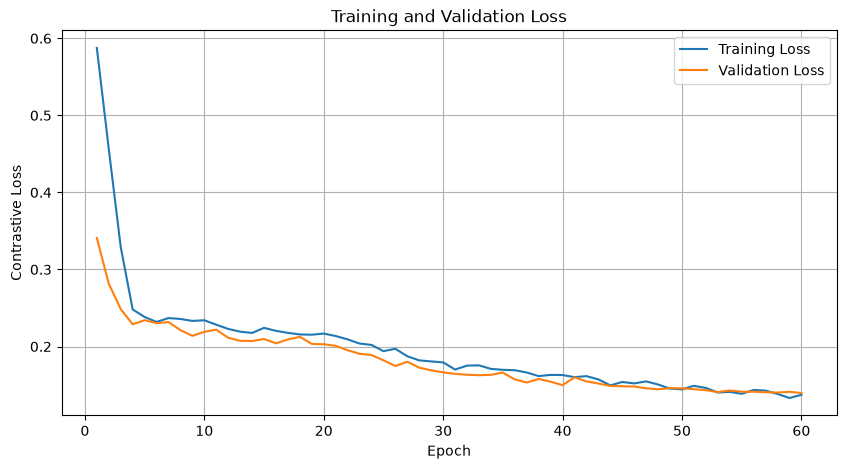

In [71]:
# ============================================================
# CELL 30: Plot training and validation loss
# ============================================================


epochs = range(

    1,

    len(
        history[
            "train_loss"
        ]
    ) + 1

)


plt.figure(

    figsize=(
        10,
        5
    )

)


plt.plot(

    epochs,

    history[
        "train_loss"
    ],

    label="Training Loss"

)


plt.plot(

    epochs,

    history[
        "validation_loss"
    ],

    label="Validation Loss"

)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Contrastive Loss"
)


plt.title(
    "Training and Validation Loss"
)


plt.legend()


plt.grid()


plt.show()

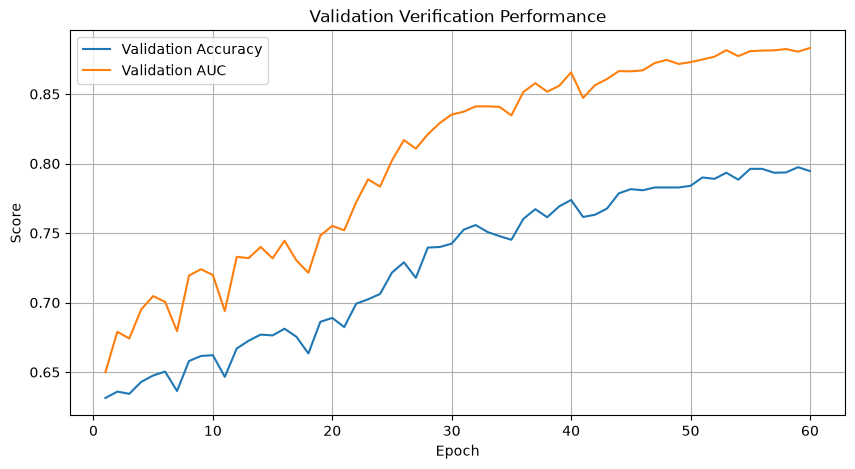

In [72]:
# ============================================================
# CELL 31: Plot validation performance
# ============================================================


plt.figure(

    figsize=(
        10,
        5
    )

)


plt.plot(

    epochs,

    history[
        "validation_accuracy"
    ],

    label="Validation Accuracy"

)


plt.plot(

    epochs,

    history[
        "validation_auc"
    ],

    label="Validation AUC"

)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Score"
)


plt.title(
    "Validation Verification Performance"
)


plt.legend()


plt.grid()


plt.show()

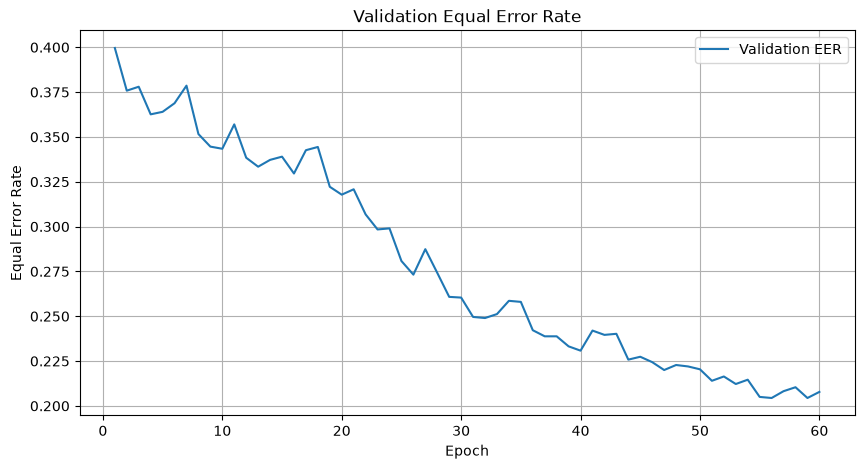

In [73]:
# ============================================================
# CELL 32: Plot validation EER
# ============================================================


plt.figure(

    figsize=(
        10,
        5
    )

)


plt.plot(

    epochs,

    history[
        "validation_eer"
    ],

    label="Validation EER"

)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Equal Error Rate"
)


plt.title(
    "Validation Equal Error Rate"
)


plt.legend()


plt.grid()


plt.show()

In [74]:
# ============================================================
# CELL 33: Load best model
# ============================================================

# weights_only=False: the checkpoint stores numpy scalars (thresholds),
# which recent PyTorch versions refuse to load by default.

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)


best_threshold = float(checkpoint["threshold"])

best_eer_threshold = float(checkpoint["eer_threshold"])


print("Best Siamese model loaded successfully.")

print("\nBackbone:", BACKBONE)

print("Best Epoch:", checkpoint["epoch"])

print("Validation AUC:", checkpoint["validation_auc"])

print("Validation Accuracy:", checkpoint["validation_accuracy"])

print("Validation EER:", checkpoint["validation_eer"])

print("Selected Threshold:", best_threshold)


Best Siamese model loaded successfully.

Backbone: resnet34
Best Epoch: 60
Validation AUC: 0.8831156800000001
Validation Accuracy: 0.7946
Validation EER: 0.20779999999999998
Selected Threshold: 0.4804176390171051


In [75]:
# ============================================================
# CELL 34: Final test evaluation
# ============================================================


test_loss, test_distances, test_labels = (

    evaluate_model(

        model,

        test_loader,

        criterion

    )

)


# ------------------------------------------------------------
# Threshold selected only from validation data
# ------------------------------------------------------------

test_predictions = predict_from_distance(

    test_distances,

    best_threshold

)


test_accuracy = accuracy_score(

    test_labels,

    test_predictions

)


test_metrics = get_validation_metrics(

    test_distances,

    test_labels

)


print("=" * 65)

print(
    "FINAL IDENTITY-DISJOINT TEST RESULTS"
)

print("=" * 65)


print(
    f"\nTest Loss: "
    f"{test_loss:.4f}"
)


print(
    f"Test Accuracy: "
    f"{test_accuracy:.4f}"
)


print(
    f"Test AUC: "
    f"{test_metrics['auc']:.4f}"
)


print(
    f"Test EER: "
    f"{test_metrics['eer']:.4f}"
)

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

FINAL IDENTITY-DISJOINT TEST RESULTS

Test Loss: 0.1397
Test Accuracy: 0.7928
Test AUC: 0.8797
Test EER: 0.2192


In [76]:
# ============================================================
# CELL 35: Test FAR and FRR
# ============================================================


test_far, test_frr = calculate_far_frr(

    test_distances,

    test_labels,

    best_threshold

)


print(
    f"False Acceptance Rate (FAR): "
    f"{test_far:.4f}"
)


print(
    f"False Rejection Rate (FRR): "
    f"{test_frr:.4f}"
)

False Acceptance Rate (FAR): 0.2476
False Rejection Rate (FRR): 0.1668


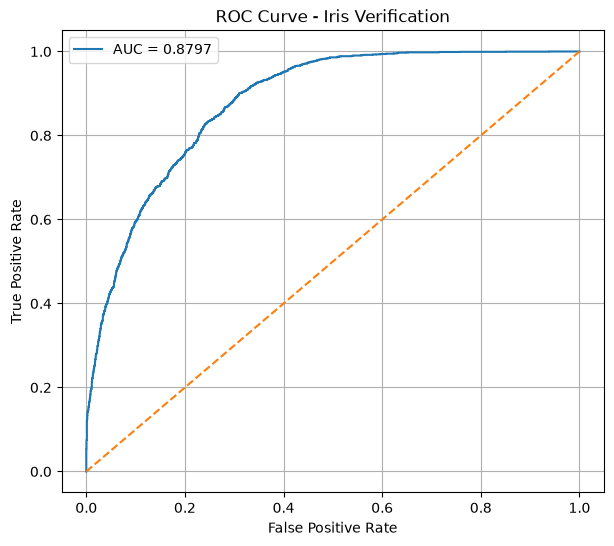

In [77]:
# ============================================================
# CELL 36: Test ROC Curve
# ============================================================


test_fpr = test_metrics[
    "fpr"
]


test_tpr = test_metrics[
    "tpr"
]


test_auc = test_metrics[
    "auc"
]


plt.figure(

    figsize=(
        7,
        6
    )

)


plt.plot(

    test_fpr,

    test_tpr,

    label=(
        f"AUC = "
        f"{test_auc:.4f}"
    )

)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"

)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ROC Curve - Iris Verification"
)


plt.legend()


plt.grid()


plt.show()

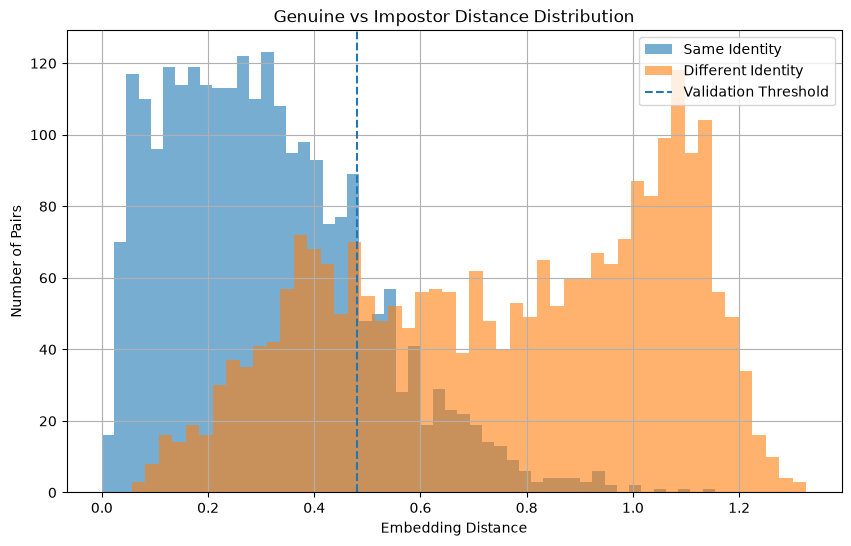

In [78]:
# ============================================================
# CELL 37: Genuine vs Impostor distance distributions
# ============================================================


genuine_distances = test_distances[
    test_labels == 0
]


impostor_distances = test_distances[
    test_labels == 1
]


plt.figure(

    figsize=(
        10,
        6
    )

)


plt.hist(

    genuine_distances,

    bins=50,

    alpha=0.6,

    label="Same Identity"

)


plt.hist(

    impostor_distances,

    bins=50,

    alpha=0.6,

    label="Different Identity"

)


plt.axvline(

    best_threshold,

    linestyle="--",

    label="Validation Threshold"

)


plt.xlabel(
    "Embedding Distance"
)


plt.ylabel(
    "Number of Pairs"
)


plt.title(
    "Genuine vs Impostor Distance Distribution"
)


plt.legend()


plt.grid()


plt.show()

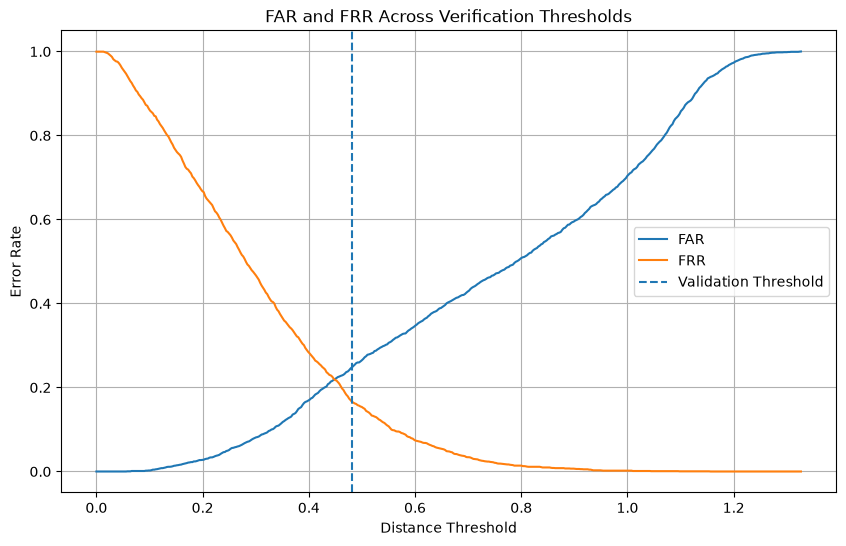

In [79]:
# ============================================================
# CELL 38: FAR and FRR curves
# ============================================================


thresholds = np.linspace(

    test_distances.min(),

    test_distances.max(),

    500

)


far_values = []

frr_values = []


for threshold in thresholds:


    far, frr = calculate_far_frr(

        test_distances,

        test_labels,

        threshold

    )


    far_values.append(
        far
    )


    frr_values.append(
        frr
    )


plt.figure(

    figsize=(
        10,
        6
    )

)


plt.plot(

    thresholds,

    far_values,

    label="FAR"

)


plt.plot(

    thresholds,

    frr_values,

    label="FRR"

)


plt.axvline(

    best_threshold,

    linestyle="--",

    label="Validation Threshold"

)


plt.xlabel(
    "Distance Threshold"
)


plt.ylabel(
    "Error Rate"
)


plt.title(
    "FAR and FRR Across Verification Thresholds"
)


plt.legend()


plt.grid()


plt.show()

In [80]:
# ============================================================
# CELL 39: Save training history
# ============================================================


history_df = pd.DataFrame(

    history

)


HISTORY_PATH = OUTPUT_DIR / (

    "training_history.csv"

)


history_df.to_csv(

    HISTORY_PATH,

    index=False

)


print(
    "Training history saved to:"
)


print(
    HISTORY_PATH
)

Training history saved to:
..\siamese_metric_learning\training_history.csv


In [81]:
# ============================================================
# CELL 40: Save final results
# ============================================================


results = {

    "best_epoch":

        checkpoint[
            "epoch"
        ],

    "best_validation_loss":

        checkpoint[
            "validation_loss"
        ],

    "best_validation_accuracy":

        checkpoint[
            "validation_accuracy"
        ],

    "best_validation_auc":

        checkpoint[
            "validation_auc"
        ],

    "best_validation_eer":

        checkpoint[
            "validation_eer"
        ],

    "test_loss":

        test_loss,

    "test_accuracy":

        test_accuracy,

    "test_auc":

        test_auc,

    "test_eer":

        test_metrics[
            "eer"
        ],

    "test_far":

        test_far,

    "test_frr":

        test_frr,

    "validation_threshold":

        best_threshold,

    "validation_eer_threshold":

        best_eer_threshold,

    "embedding_dimension":

        EMBEDDING_DIM

}


results_df = pd.DataFrame(

    [results]

)


RESULTS_PATH = OUTPUT_DIR / (

    "final_results.csv"

)


results_df.to_csv(

    RESULTS_PATH,

    index=False

)


display(
    results_df
)

,best_epoch,best_validation_loss,best_validation_accuracy,best_validation_auc,best_validation_eer,test_loss,test_accuracy,test_auc,test_eer,test_far,test_frr,validation_threshold,validation_eer_threshold,embedding_dimension
0,60,0.139578,0.7946,0.883116,0.2078,0.139694,0.7928,0.879686,0.2192,0.2476,0.1668,0.480418,0.459311,128


In [82]:
# ============================================================
# CELL 41: Save experiment configuration
# ============================================================


configuration = {

    "seed": SEED,

    "backbone": BACKBONE,

    "image_size": IMAGE_SIZE,

    "batch_size_pairs": BATCH_SIZE,

    "epochs_requested": NUM_EPOCHS,

    "backbone_lr": BACKBONE_LR,

    "head_lr": HEAD_LR,

    "weight_decay": WEIGHT_DECAY,

    "embedding_dimension": EMBEDDING_DIM,

    "contrastive_margin": CONTRASTIVE_MARGIN,

    "training_pairs_per_epoch": TRAIN_PAIRS_PER_EPOCH,

    "validation_pairs": VALIDATION_PAIRS,

    "test_pairs": TEST_PAIRS

}


CONFIG_PATH = OUTPUT_DIR / "experiment_configuration.csv"


pd.DataFrame([configuration]).to_csv(
    CONFIG_PATH,
    index=False
)


print("Experiment configuration saved.")


Experiment configuration saved.


In [83]:
# ============================================================
# CELL 42: Final Summary
# ============================================================


print("=" * 70)

print(
    "NOTEBOOK 5 COMPLETED SUCCESSFULLY"
)

print("=" * 70)


print(
    "\nCLASSICAL SIAMESE METRIC LEARNING RESULTS"
)


print(
    f"\nEmbedding Dimension: "
    f"{EMBEDDING_DIM}"
)


print(
    f"Best Epoch: "
    f"{checkpoint['epoch']}"
)


print(
    f"Best Validation Accuracy: "
    f"{checkpoint['validation_accuracy']:.4f}"
)


print(
    f"Best Validation AUC: "
    f"{checkpoint['validation_auc']:.4f}"
)


print(
    f"Best Validation EER: "
    f"{checkpoint['validation_eer']:.4f}"
)


print(
    f"\nFinal Test Accuracy: "
    f"{test_accuracy:.4f}"
)


print(
    f"Final Test AUC: "
    f"{test_auc:.4f}"
)


print(
    f"Final Test EER: "
    f"{test_metrics['eer']:.4f}"
)


print(
    f"Final Test FAR: "
    f"{test_far:.4f}"
)


print(
    f"Final Test FRR: "
    f"{test_frr:.4f}"
)


print(
    f"\nValidation-selected Threshold: "
    f"{best_threshold:.4f}"
)


print(
    "\nSaved Model:"
)


print(
    BEST_MODEL_PATH
)


print(
    "\nOutput Directory:"
)


print(
    OUTPUT_DIR
)


print(
    "\n✓ Notebook 5 is complete."
)

NOTEBOOK 5 COMPLETED SUCCESSFULLY

CLASSICAL SIAMESE METRIC LEARNING RESULTS

Embedding Dimension: 128
Best Epoch: 60
Best Validation Accuracy: 0.7946
Best Validation AUC: 0.8831
Best Validation EER: 0.2078

Final Test Accuracy: 0.7928
Final Test AUC: 0.8797
Final Test EER: 0.2192
Final Test FAR: 0.2476
Final Test FRR: 0.1668

Validation-selected Threshold: 0.4804

Saved Model:
..\siamese_metric_learning\best_siamese_metric_model.pth

Output Directory:
..\siamese_metric_learning

✓ Notebook 5 is complete.
